# Trabalho Prático 2 - Modelos

Aluno: João Gabriel Angelo Bradachi - 5078

Professor: Fabrício Aguiar Silva

O objetivo deste trabalho é aplicar técnicas de engenharia de atributos e ajustar os parâmetros do algoritmo adotado para melhorar os resultados de classificação do problema de previsão de churn.

Algorítmo escolhido: XGBoost

## Parte 1: Engenharia de atributos

1. Após entender e conhecer bem os atributos do conjunto de dados, aplicar técnicas de engenharia
de atributos em dados numéricos e categóricos. A decisão deve ser baseada em fundamentos de
acordo com o problema e as características dos dados.
2. Após a etapa 1, avaliar a necessidade e aplicar técnicas de seleção de atributos, para que sejam
utilizados apenas os atributos mais relevantes para o modelo.

In [1]:
%pip install setuptools==81.0.0
%pip install pandas numpy matplotlib seaborn scipy scikit-learn tpot optuna xgboost fg-data-profiling ipywidgets

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [113]:
# imports

import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

from data_profiling import ProfileReport

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer ,  make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from xgboost import XGBClassifier
import optuna
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

import tpot
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score

from sklearn.metrics import RocCurveDisplay

In [84]:
df_original = pd.read_csv("churn.csv")
df = df_original

In [5]:
df.describe()

,Unnamed: 0,age,days_since_last_login,avg_time_spent,avg_transaction_value,points_in_wallet,churn_risk_score
count,36992.000000,36992.000000,36992.000000,36992.000000,36992.000000,33549.000000,36992.000000
mean,18495.500000,37.118161,-41.915576,243.472334,29271.194003,686.882199,0.540982
std,10678.814916,15.867412,228.819900,398.289149,19444.806226,194.063624,0.498324
min,0.000000,10.000000,-999.000000,-2814.109110,800.460000,-760.661236,0.000000
25%,9247.750000,23.000000,8.000000,60.102500,14177.540000,616.150000,0.000000
50%,18495.500000,37.000000,12.000000,161.765000,27554.485000,697.620000,1.000000
75%,27743.250000,51.000000,16.000000,356.515000,40855.110000,763.950000,1.000000
max,36991.000000,64.000000,26.000000,3235.578521,99914.050000,2069.069761,1.000000


In [13]:
for column in df.columns:
    print(f"Valores diferentes de {column}: {len(df[column].value_counts())}")


Valores diferentes de Unnamed: 0: 36992
Valores diferentes de age: 55
Valores diferentes de gender: 3
Valores diferentes de security_no: 36992
Valores diferentes de region_category: 3
Valores diferentes de membership_category: 6
Valores diferentes de joining_date: 1096
Valores diferentes de joined_through_referral: 3
Valores diferentes de referral_id: 11359
Valores diferentes de preferred_offer_types: 3
Valores diferentes de medium_of_operation: 4
Valores diferentes de internet_option: 3
Valores diferentes de last_visit_time: 30101
Valores diferentes de days_since_last_login: 27
Valores diferentes de avg_time_spent: 25961
Valores diferentes de avg_transaction_value: 36894
Valores diferentes de avg_frequency_login_days: 1654
Valores diferentes de points_in_wallet: 23699
Valores diferentes de used_special_discount: 2
Valores diferentes de offer_application_preference: 2
Valores diferentes de past_complaint: 2
Valores diferentes de complaint_status: 5
Valores diferentes de feedback: 9
Val

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36992 entries, 0 to 36991
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Unnamed: 0                    36992 non-null  int64  
 1   age                           36992 non-null  int64  
 2   gender                        36992 non-null  object 
 3   security_no                   36992 non-null  object 
 4   region_category               31564 non-null  object 
 5   membership_category           36992 non-null  object 
 6   joining_date                  36992 non-null  object 
 7   joined_through_referral       36992 non-null  object 
 8   referral_id                   36992 non-null  object 
 9   preferred_offer_types         36704 non-null  object 
 10  medium_of_operation           36992 non-null  object 
 11  internet_option               36992 non-null  object 
 12  last_visit_time               36992 non-null  object 
 13  d

Unnamed: 0 e security_no são colunas de identificação unicas, podem ser retiradas

region_category, points_in_wallet, preferred_offer_types possuem algumas linhas com valores nulos a priori vamos colocar valores comuns nela (média e moda), mas algo mais sofisticado é criar um modelo que complete esses valores faltantes

joining_date é atributo temporal, podemos dividir em ano, mês e dia

avg_frequency_login_days possúi linhas de erro (nulo?)
joined_through_referral linhas de erro (nulo?)

In [78]:
def referral_id(df):
    if df["referral_id"] != "xxxxxxxx":
        df["joined_through_referral"] = "Yes"
    else:
        df["joined_through_referral"] = "No"
    return df

def avg_frequency_login_days(linha):
    if linha == 'Error':
        return None
    else: return linha

def medium_of_operation(linha):
    if linha == '?':
        return None
    else: return linha
    
def gender(linha):
    if linha == 'Unknown':
        return None
    else: return linha

In [85]:
df = df.drop(columns=["Unnamed: 0", "security_no"])
df[["joining_year", "joining_month", "joining_day"]] = df["joining_date"].str.split("-", expand=True)
df[["last_visit_time_hour", "last_visit_time_min", "last_visit_time_sec"]] = df["last_visit_time"].str.split(":", expand=True)
df = df.apply(referral_id, axis=1)
df["avg_frequency_login_days"] = df["avg_frequency_login_days"].apply(avg_frequency_login_days)
df["medium_of_operation"] = df["medium_of_operation"].apply(medium_of_operation)
df["gender"] = df["gender"].apply(gender)

In [86]:
df['age'] = df['age'].astype('int64') 
df['gender'] = df['gender'].astype('object') 
df['region_category'] = df['region_category'].astype('object')
df['membership_category'] = df['membership_category'].astype('object') 
df['joining_date'] = df['joining_date'].astype('object') 
df['joined_through_referral'] = df['joined_through_referral'].astype('object') 
df['referral_id'] = df['referral_id'].astype('object') 
df['preferred_offer_types'] = df['preferred_offer_types'].astype('object')
df['medium_of_operation'] = df['medium_of_operation'].astype('object') 
df['internet_option'] = df['internet_option'].astype('object') 
df['last_visit_time'] = df['last_visit_time'].astype('object') 
df['days_since_last_login'] = df['days_since_last_login'].astype('int64') 
df['avg_time_spent'] = df['avg_time_spent'].astype('float64') 
df['avg_transaction_value'] = df['avg_transaction_value'].astype('float64') 
df['avg_frequency_login_days'] = df['avg_frequency_login_days'].astype('float64') 
df['points_in_wallet'] = df['points_in_wallet'].astype('float64')
df['used_special_discount'] = df['used_special_discount'].astype('object') 
df['offer_application_preference'] = df['offer_application_preference'].astype('object') 
df['past_complaint'] = df['past_complaint'].astype('object') 
df['complaint_status'] = df['complaint_status'].astype('object') 
df['feedback'] = df['feedback'].astype('object') 
df['joining_year'] = df['joining_year'].astype('int64') 
df['joining_month'] = df['joining_month'].astype('int64') 
df['joining_day'] = df['joining_day'].astype('int64') 
df['last_visit_time_hour'] = df['last_visit_time_hour'].astype('int64') 
df['last_visit_time_min'] = df['last_visit_time_min'].astype('int64') 
df['last_visit_time_sec'] = df['last_visit_time_sec'].astype('int64') 
df['churn_risk_score'] = df['churn_risk_score'].astype('int64') 

In [81]:
df

,age,gender,region_category,membership_category,joining_date,joined_through_referral,referral_id,preferred_offer_types,medium_of_operation,internet_option,...,past_complaint,complaint_status,feedback,churn_risk_score,joining_year,joining_month,joining_day,last_visit_time_hour,last_visit_time_min,last_visit_time_sec
0,18,F,Village,Platinum Membership,2017-08-17,No,xxxxxxxx,Gift Vouchers/Coupons,None,Wi-Fi,...,No,Not Applicable,Products always in Stock,0,2017,8,17,16,8,2
1,32,F,City,Premium Membership,2017-08-28,Yes,CID21329,Gift Vouchers/Coupons,Desktop,Mobile_Data,...,Yes,Solved,Quality Customer Care,0,2017,8,28,12,38,13
2,44,F,Town,No Membership,2016-11-11,Yes,CID12313,Gift Vouchers/Coupons,Desktop,Wi-Fi,...,Yes,Solved in Follow-up,Poor Website,1,2016,11,11,22,53,21
3,37,M,City,No Membership,2016-10-29,Yes,CID3793,Gift Vouchers/Coupons,Desktop,Mobile_Data,...,Yes,Unsolved,Poor Website,1,2016,10,29,15,57,50
4,31,F,City,No Membership,2017-09-12,No,xxxxxxxx,Credit/Debit Card Offers,Smartphone,Mobile_Data,...,Yes,Solved,Poor Website,1,2017,9,12,15,46,44
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36987,46,F,NaN,Basic Membership,2017-09-21,No,xxxxxxxx,Credit/Debit Card Offers,Desktop,Wi-Fi,...,Yes,No Information Available,No reason specified,1,2017,9,21,4,14,5
36988,29,F,Town,Basic Membership,2016-06-27,No,xxxxxxxx,Without Offers,Smartphone,Wi-Fi,...,No,Not Applicable,Poor Customer Service,1,2016,6,27,23,18,31
36989,23,F,NaN,Basic Membership,2016-09-11,Yes,CID3838,Gift Vouchers/Coupons,Desktop,Wi-Fi,...,Yes,Unsolved,Poor Website,1,2016,9,11,3,50,25
36990,53,M,Village,Platinum Membership,2017-06-15,No,xxxxxxxx,Gift Vouchers/Coupons,Smartphone,Mobile_Data,...,No,Not Applicable,No reason specified,0,2017,6,15,9,50,3


In [87]:
df = df.drop(columns=["joining_date", "last_visit_time"])

In [ ]:
report = ProfileReport(df,explorative=True, sensitive=True)
report.to_notebook_iframe()

### Alertas gerados pelo Profilling report:


churn_risk_score is highly overall correlated with membership_category and points_in_wallet	High correlation

complaint_status is highly overall correlated with past_complaint	High correlation

membership_category is highly overall correlated with churn_risk_score	High correlation

offer_application_preference is highly overall correlated with used_special_discount	High correlation

past_complaint is highly overall correlated with complaint_status	High correlation

points_in_wallet is highly overall correlated with churn_risk_score	High correlation

used_special_discount is highly overall correlated with offer_application_preference	High correlation

region_category has 5428 (14.7%) missing values	Missing

medium_of_operation has 5393 (14.6%) missing values	Missing

avg_frequency_login_days has 3522 (9.5%) missing values	Missing

points_in_wallet has 3443 (9.3%) missing values	Missing

last_visit_time_hour has 1512 (4.1%) zeros	Zeros

last_visit_time_min has 645 (1.7%) zeros	Zeros

last_visit_time_sec has 630 (1.7%) zeros	Zeros

In [ ]:
def train_validation_test_split(X, y, test_size=0.15, val_size=0.15, random_state=42):
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    val_size_ajustado = val_size / (1 - test_size)

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val,
        y_train_val,
        test_size=val_size_ajustado,
        random_state=random_state,
    )

    return X_train, X_val, X_test, y_train, y_val, y_test



### Baseline

In [116]:
# Vamos criar um baseline, XGB sem tratar nada dos parâmetros e sem fazer ajuste de
# hiper parametros, vamos apenas dar um dropna
df_baseline = df

X = df_baseline.drop(columns=['churn_risk_score'])
y = df_baseline['churn_risk_score']

X_train_baseline, X_val_baseline, X_test_baseline, y_train_baseline, y_val_baseline, y_test_baseline = train_validation_test_split(X, y)

cat_pipeline = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_pipeline, make_column_selector(dtype_include=['object', 'category']))
    ],
    remainder='passthrough' 
)

model_baseline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classificador', XGBClassifier())
])

model_baseline.fit(X_train_baseline, y_train_baseline)

scores = cross_val_score(model_baseline, X_val_baseline, y_val_baseline, scoring='accuracy', cv=5)

print(f'acurácia no cross validation: {scores.mean()}')
print("Teste: ")

previsoes = model_baseline.predict(X_test_baseline)
print("\nRelatório de Classificação:")
print(classification_report(y_test_baseline, previsoes, digits=5))


acurácia no cross validation: 0.9344014167458712
Teste: 

Relatório de Classificação:
              precision    recall  f1-score   support

           0    0.94209   0.90909   0.92530      2541
           1    0.92541   0.95279   0.93890      3008

    accuracy                        0.93278      5549
   macro avg    0.93375   0.93094   0.93210      5549
weighted avg    0.93305   0.93278   0.93267      5549



In [118]:
def objective_baseline(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.5, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
    }

    model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classificador', XGBClassifier(**params))
    ])

    model.fit(X_train_baseline, y_train_baseline)

  # Validação cruzada com 5 folds
    scores = cross_val_score(model, X_val_baseline, y_val_baseline, cv=5, scoring='accuracy', verbose=1)
    return scores.mean()

study = optuna.create_study(direction='maximize')

study.optimize(objective_baseline, n_trials=100)
print('Melhor acurácia:', study.best_value)
print('Melhores parâmetros:', study.best_params)

print("Métricas com modelo e hiper-parametros ajustados")

model_baseline_ajustado = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classificador', XGBClassifier(**study.best_params))
])
model_baseline_ajustado.fit(X_train_baseline, y_train_baseline)

print(f'Extraindo métricas do dataset teste:')

previsoes = model_baseline_ajustado.predict(X_test_baseline)
print("\nRelatório de Classificação:")
print(classification_report(y_test_baseline, previsoes, digits=5))

[I 2026-10-29 16:05:31,450] A new study created in memory with name: no-name-d7439fa0-3da9-4010-9305-327a54173602
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.9s finished
[I 2026-10-29 16:05:34,067] Trial 0 finished with value: 0.9331390181886124 and parameters: {'n_estimators': 166, 'max_depth': 4, 'learning_rate': 0.05372175673316247, 'subsample': 0.7559914666912764, 'colsample_bytree': 0.881728806061892}. Best is trial 0 with value: 0.9331390181886124.
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.0s finished
[I 2026-10-29 16:05:35,842] Trial 1 finished with value: 0.9266518818186988 and parameters: {'n_estimators': 70, 'max_depth': 9, 'learning_rate': 0.16132451519997848, 'subsample': 0.9844986644867918, 'colsample_bytree': 0.5684213984874464}. Best is trial 0 with value: 0.9331390181886124.
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    4.5s finished
[I 2026-10-29 16:05:41,116] Trial 2 finished with value: 0.9225070877911274 and parameters: {'n_es

Melhor acurácia: 0.9363817740192854
Melhores parâmetros: {'n_estimators': 239, 'max_depth': 7, 'learning_rate': 0.042320428561274465, 'subsample': 0.9551187127779149, 'colsample_bytree': 0.8527895517241956}
Métricas com modelo e hiper-parametros ajustados
Extraindo métricas do dataset teste:

Relatório de Classificação:
              precision    recall  f1-score   support

           0    0.93557   0.92011   0.92778      2541
           1    0.93344   0.94648   0.93991      3008

    accuracy                        0.93440      5549
   macro avg    0.93451   0.93329   0.93385      5549
weighted avg    0.93442   0.93440   0.93436      5549



### Aplicando engenharia de atributos e ajuste de hiper parâmetros

In [92]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean'))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, make_column_selector(dtype_include=['number'])),
        ('cat', cat_pipeline, make_column_selector(dtype_include=['object', 'category']))
    ],
    remainder='passthrough' 
)

In [108]:
X = df.drop(columns=['churn_risk_score'])
y = df['churn_risk_score']

X_train, X_val, X_test, y_train, y_val, y_test = train_validation_test_split(X, y)

In [ ]:
def objective_XGB(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.5, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
    }

    model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classificador', XGBClassifier(**params))
    ])

    model.fit(X_train, y_train)

  # Validação cruzada com 5 folds
    scores = cross_val_score(model, X_val, y_val, cv=5, scoring='accuracy', verbose=1)
    return scores.mean()

def ajusta_parametros(objective, modelo, nome=None):
    study = optuna.create_study(direction='maximize')

    study.optimize(objective, n_trials=100)
    print('Melhor acurácia:', study.best_value)
    print('Melhores parâmetros:', study.best_params)

    print("Métricas com modelo e hiper-parametros ajustados")
    
    model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classificador', modelo(**study.best_params))
    ])
    model.fit(X_train, y_train)

    print(f'Extraindo métricas do dataset teste:')

    previsoes = model.predict(X_test)
    print("\nRelatório de Classificação:")
    print(classification_report(y_test, previsoes, digits=5))
    return model

In [ ]:
ajusta_parametros(objective_XGB, XGBClassifier)

[I 2026-10-29 15:41:13,157] A new study created in memory with name: no-name-beb21efd-ae51-4e72-aa29-d2b718c2c794
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    3.3s finished
[I 2026-10-29 15:41:18,256] Trial 0 finished with value: 0.9302566227182998 and parameters: {'n_estimators': 169, 'max_depth': 8, 'learning_rate': 0.021402207182429456, 'subsample': 0.9339211155615691, 'colsample_bytree': 0.9241377580889432}. Best is trial 0 with value: 0.9302566227182998.
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.0s finished
[I 2026-10-29 15:41:20,630] Trial 1 finished with value: 0.9289935742776139 and parameters: {'n_estimators': 72, 'max_depth': 5, 'learning_rate': 0.06495584221931563, 'subsample': 0.7260955420790237, 'colsample_bytree': 0.7043159504861585}. Best is trial 0 with value: 0.9302566227182998.
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    2.8s finished
[I 2026-10-29 15:41:25,931] Trial 2 finished with value: 0.9322382797585682 and parameters: {'n_

Melhor acurácia: 0.9347616146353748
Melhores parâmetros: {'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.03761690125941556, 'subsample': 0.9175535525109433, 'colsample_bytree': 0.7803814040845998}
Métricas com modelo e hiper-parametros ajustados
Extraindo métricas do dataset teste:

Relatório de Classificação:
              precision    recall  f1-score   support

           0    0.94037   0.91224   0.92609      2541
           1    0.92769   0.95113   0.93926      3008

    accuracy                        0.93332      5549
   macro avg    0.93403   0.93168   0.93268      5549
weighted avg    0.93349   0.93332   0.93323      5549



In [109]:
best_params = {'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.03761690125941556, 'subsample': 0.9175535525109433, 'colsample_bytree': 0.7803814040845998}
model_bradas = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classificador', XGBClassifier(**best_params))
    ])
model_bradas.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['age','gender','region_category',...,'last_visit_time_hour', 'last_visit_time_min','last_visit_time_sec']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``re

In [ ]:
# Executando com TPOT

pre_processador_tpot = ColumnTransformer(
    transformers=[
        ('cat', cat_pipeline, make_column_selector(dtype_include=['object', 'category']))
    ])

modelo_pipeline_tpot = Pipeline(steps=[
      ('pre_processamento', pre_processador_tpot),
      ('classificador', tpot.TPOTClassifier(max_time_mins=15, verbose=2))
  ])

modelo_pipeline_tpot.fit(X_train, y_train)

print("Fazendo validação")

scores = cross_val_score(modelo_pipeline_tpot, X_val, y_val, scoring='accuracy', cv=5)

print(f'acurácia no cross validation: {scores.mean()}')

print("Fazendo teste")
previsoes = modelo_pipeline_tpot.predict(X_test)

print("\nRelatório de Classificação:")
print(classification_report(y_test, previsoes, digits=5))

tpot_instancia = modelo_pipeline_tpot.named_steps["classificador"]

print(tpot_instancia.fitted_pipeline_)

Generation: : 0it [00:00, ?it/s]/home/bradas/Documentos/github/ml-engineering/.venv/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Generation: : 1it [24:53, 1493.95s/it]


Fazendo validação
acurácia no cross validation: 0.9344014167458712
Fazendo teste

Relatório de Classificação:
              precision    recall  f1-score   support

           0    0.77185   0.97324   0.86092      2541
           1    0.97100   0.75698   0.85074      3008

    accuracy                        0.85601      5549
   macro avg    0.87142   0.86511   0.85583      5549
weighted avg    0.87981   0.85601   0.85540      5549

Pipeline(steps=[('maxabsscaler', MaxAbsScaler()),
                ('selectfwe', SelectFwe(alpha=0.0006221812532)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                         

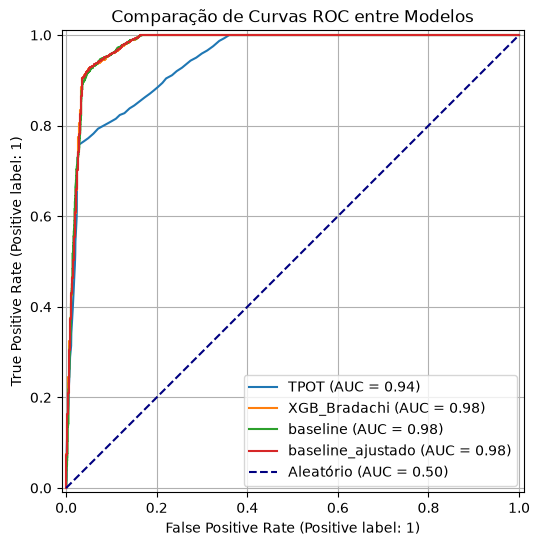

In [119]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(modelo_pipeline_tpot, X_test, y_test, ax=ax, name='TPOT')
RocCurveDisplay.from_estimator(model_bradas, X_test, y_test, ax=ax, name='XGB_Bradachi')
RocCurveDisplay.from_estimator(model_baseline, X_test_baseline, y_test_baseline, ax=ax, name='baseline')
RocCurveDisplay.from_estimator(model_baseline_ajustado, X_test_baseline, y_test_baseline, ax=ax, name='baseline_ajustado')

# 6. Personalizar o gráfico
ax.plot([0, 1], [0, 1], linestyle='--', color='navy', label='Aleatório (AUC = 0.50)')
ax.set_title('Comparação de Curvas ROC entre Modelos')
ax.legend(loc='lower right')
ax.grid(True)

# 7. Exibir o gráfico
plt.show()

# XGBOOST

Extreme Gradient Boosting

É um algoritmo do tipo ensemble que combina várias árvores de decisão treinadas em sequência

Usa o método de boosting, onde cada árvore nova é criada para corrigir os erros cometidos pela árvore anterior

Sobre overfitting: Possui parâmetros embutidos de regularização (L1 e L2) que punem a complexidade das árvores e evitam o sobreajuste

Otimizado para dados esparsos

Paralelismo eficiente

Por mais que seja uma arvore de decisão com boosting, ele é quase caixa preta. Precisa de ferramentas extras para entender o que influenciou o resultado (interpretação existe porém não trivial)

Treinamento pesado mas usa paralelismo e otimizações de hardware para ser muito mais rápido do que outros métodos de boosting clássicos

## Conclusão:

Com esse trabalho prático pude aplicar todo conhecimento obtido da matéria para fazer uma análise aprofundada sobre o algorítmo XGBoost.